# Multi-Gene Genetic Variant Pathogenicity Prediction

**Notebook 01 – Dataset Exploration, Cleaning, and Baseline Model**

An interpretable machine-learning study that classifies ClinVar missense variants as *pathogenic* (1) or *benign* (0) from simple, computationally derived features.

**Genes:** CFTR, BRCA1, TP53, HBB, LDLR, PAH
**Data source:** NCBI ClinVar (germline classifications), search `((CFTR[gene] OR BRCA1[gene] OR TP53[gene] OR HBB[gene] OR LDLR[gene] OR PAH[gene]) AND missense_variant[molcons])`

> **Scope and safety.** This is an educational research project. The model learns patterns in one ClinVar snapshot. It is **not** a clinical diagnostic tool and must not be used for patient diagnosis or medical decisions. SHAP explains model behaviour, not biology. Output probabilities are not clinical risk estimates.

**Contents**
1. Project introduction
2. Imports and configuration
3. Load the ClinVar dataset
4. Initial dataset inspection
5. Data cleaning and target labelling
6. Gene and protein feature extraction
7. Final dataset validation
8. Exploratory data analysis
9. Feature selection
10. Train–test split
11. Preprocessing pipeline
12. Random Forest training
13. Model evaluation
14. Additional validation (gene-held-out and baselines)
15. SHAP explainability
16. Save processed data, model, and lookup table
17. Limitations and conclusion

> **Execution note:** Run this notebook from top to bottom with **Run All** after restarting the kernel. Do not run an evaluation cell by itself in a fresh session: variables such as `y_test`, `X_test`, `rf_model`, and `test_predictions` are created by earlier cells. The confusion-matrix and error-analysis cells below reuse the notebook's existing `test_predictions` variable; no separate `y_pred` variable is required.


## 2. Imports and Configuration

All imports and constants live here. The project root is found by searching upward from the working directory, so the notebook runs whether it is launched from `notebooks/` or the project root.

In [2]:
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import LeaveOneGroupOut, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
TARGET_GENES = ["CFTR", "BRCA1", "TP53", "HBB", "LDLR", "PAH"]
RF_PARAMS = {
    "n_estimators": 300,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}


def find_project_root(start=None):
    """Walk upward from the working directory until the project folders are found."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Expected 'data/raw' and 'notebooks' folders "
        "in the working directory or one of its parents."
    )


PROJECT_ROOT = find_project_root()
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "clinvar_download_20261107_103417.tsv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

print("Project root:", PROJECT_ROOT)
print("Raw file exists:", RAW_FILE.exists())

Project root: C:\Users\umair\OneDrive\Desktop\Genetic-Variant-Pathogenicity
Raw file exists: True


## 3. Load the ClinVar Dataset

The file is read by **column name**, not by position. If a column is missing or renamed, loading fails immediately instead of silently reading the wrong data.

In [3]:
EXPECTED_COLUMNS = [
    "Name", "Gene(s)", "Protein change", "Condition(s)", "Accession",
    "GRCh37Chromosome", "GRCh37Location", "GRCh38Chromosome", "GRCh38Location",
    "VariationID", "AlleleID(s)", "dbSNP ID", "Canonical SPDI",
    "Variant type", "Molecular consequence", "Germline classification",
    "Germline date last evaluated", "Germline review status",
    "Somatic clinical impact", "Somatic clinical impact date last evaluated",
    "Somatic clinical impact review status", "Oncogenicity classification",
    "Oncogenicity date last evaluated", "Oncogenicity review status",
]

raw_df = pd.read_csv(RAW_FILE, sep="\t", usecols=EXPECTED_COLUMNS, low_memory=False)

print("Records loaded:", len(raw_df))
print("Columns loaded:", raw_df.shape[1])

Records loaded: 13992
Columns loaded: 24


## 4. Initial Dataset Inspection

Basic structure, data types, missing values, and duplicate checks on the **unfiltered** data.

In [4]:
display(raw_df.dtypes.rename("dtype").to_frame())

missing = raw_df.isna().sum().rename("Missing").to_frame()
missing["Percent"] = (missing["Missing"] / len(raw_df) * 100).round(2)
display(missing.sort_values("Percent", ascending=False))

print("Fully duplicated rows:", raw_df.duplicated().sum())
print("Duplicate VariationID values:", raw_df["VariationID"].duplicated().sum())
print("Duplicate Canonical SPDI values:", raw_df["Canonical SPDI"].duplicated().sum())

,dtype
Name,object
Gene(s),object
Protein change,object
Condition(s),object
Accession,object
GRCh37Chromosome,object
GRCh37Location,object
GRCh38Chromosome,object
GRCh38Location,object
VariationID,int64


,Missing,Percent
Somatic clinical impact date last evaluated,13885,99.24
Somatic clinical impact,13874,99.16
Somatic clinical impact review status,13874,99.16
Oncogenicity date last evaluated,13817,98.75
Oncogenicity classification,13814,98.73
Oncogenicity review status,13814,98.73
dbSNP ID,1998,14.28
Germline date last evaluated,1280,9.15
Germline classification,1095,7.83
Germline review status,1095,7.83


Fully duplicated rows: 0
Duplicate VariationID values: 0
Duplicate Canonical SPDI values: 0


## 5. Data Cleaning and Target Labelling

The binary target `Label` comes from `Germline classification`:

- Pathogenic, Likely pathogenic, Pathogenic/Likely pathogenic → **1**
- Benign, Likely benign, Benign/Likely benign → **0**

Every other value (uncertain, conflicting, drug response, "other", missing, and so on) is excluded from training because it has no clear binary meaning. The table below shows exactly how many records each category contributes.

In [5]:
LABEL_MAP = {
    "Pathogenic": 1,
    "Likely pathogenic": 1,
    "Pathogenic/Likely pathogenic": 1,
    "Benign": 0,
    "Likely benign": 0,
    "Benign/Likely benign": 0,
}

classification_label = raw_df["Germline classification"].map(LABEL_MAP)
is_labelled = classification_label.notna()

label_audit = (
    raw_df.assign(Included=is_labelled)
    .assign(Classification=raw_df["Germline classification"].fillna("(missing)"))
    .groupby("Classification")
    .agg(Records=("VariationID", "size"), Included=("Included", "sum"))
)
label_audit["Excluded"] = label_audit["Records"] - label_audit["Included"]
display(label_audit.sort_values("Records", ascending=False))

labelled_df = raw_df.loc[is_labelled].copy()
labelled_df["Label"] = classification_label.loc[is_labelled].astype(int)

print("Records before labelling:", len(raw_df))
print("Records excluded (unsupported or missing classification):", int((~is_labelled).sum()))
print("Records with a binary label:", len(labelled_df))
print("\nLabel check (missing labels):", labelled_df["Label"].isna().sum())

,Records,Included,Excluded
Classification,,,
Uncertain significance,5964,0,5964
Conflicting classifications of pathogenicity,3686,0,3686
(missing),1095,0,1095
Likely pathogenic,1014,1014,0
Pathogenic,644,644,0
Likely benign,529,529,0
Pathogenic/Likely pathogenic,495,495,0
Benign,200,200,0
other,177,0,177


Records before labelling: 13992
Records excluded (unsupported or missing classification): 11080
Records with a binary label: 2912

Label check (missing labels): 0


## 6. Gene and Protein Feature Extraction

### Gene
`Gene(s)` can list several genes. A record is kept only when it names **exactly one** of the six selected genes. Records that name two or more selected genes, or none (including missing values), are excluded and listed with the reason. Non-selected genes in the same field do not cause exclusion.

### Protein substitution
The amino acid substitution is read from the **`Name` column only**, which gives the transcript-level notation (for example `(p.His318Gln)`). The `Protein change` column often lists several isoform substitutions, so it is **not** used as a fallback. A record is kept only when `Name` contains **exactly one** single-residue substitution. Records with zero, or two or more, substitutions are excluded and listed with the reason, so they can be investigated instead of guessed.

In [6]:
def extract_target_gene(gene_field):
    """
    Return (gene, issue) for a pipe-separated Gene(s) field.
    A record is accepted only when it names exactly one selected target gene.
    Repeated mentions of the same gene count once.
    """
    if pd.isna(gene_field) or not str(gene_field).strip():
        return (None, "Gene(s) is missing")
    genes = [g.strip() for g in str(gene_field).split("|") if g.strip()]
    selected = sorted({g for g in genes if g in TARGET_GENES})
    if len(selected) == 1:
        return (selected[0], None)
    if len(selected) == 0:
        return (None, "No selected target gene in Gene(s)")
    return (None, f"Multiple selected target genes in Gene(s) ({len(selected)})")


gene_results = labelled_df["Gene(s)"].apply(extract_target_gene).tolist()
gene_df = pd.DataFrame(
    gene_results,
    index=labelled_df.index,
    columns=["Gene", "Gene_Issue"],
)
labelled_df[gene_df.columns] = gene_df

gene_issues = labelled_df.loc[labelled_df["Gene_Issue"].notna()]
print("Records excluded during gene extraction:", len(gene_issues))
display(gene_issues["Gene_Issue"].value_counts().rename("Records").to_frame())
display(
    gene_issues[["VariationID", "Gene(s)", "Name", "Gene_Issue"]]
    .sort_values("Gene_Issue")
)

print("\nAccepted records per selected gene:")
display(
    labelled_df.loc[labelled_df["Gene_Issue"].isna(), "Gene"]
    .value_counts()
    .rename("Records")
    .to_frame()
)

Records excluded during gene extraction: 0


,Records
Gene_Issue,


,VariationID,Gene(s),Name,Gene_Issue



Accepted records per selected gene:


,Records
Gene,
LDLR,799
BRCA1,744
PAH,513
TP53,431
CFTR,305
HBB,120


In [7]:
AA_3_TO_1 = {
    "Ala": "A", "Arg": "R", "Asn": "N", "Asp": "D", "Cys": "C",
    "Glu": "E", "Gln": "Q", "Gly": "G", "His": "H", "Ile": "I",
    "Leu": "L", "Lys": "K", "Met": "M", "Phe": "F", "Pro": "P",
    "Ser": "S", "Thr": "T", "Trp": "W", "Tyr": "Y", "Val": "V",
}

# Matches exactly one single-residue substitution in parentheses, e.g. (p.His318Gln).
# Complex changes such as (p.Gln359_Thr360delinsLysLys) do not match.
SUBSTITUTION_PATTERN = re.compile(r"\(p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2})\)")


def parse_single_substitution(name):
    """
    Return (position, original_aa, new_aa, issue).
    A record is accepted only when Name contains exactly one single-residue
    amino acid substitution. issue is None when parsing succeeds.
    """
    if not isinstance(name, str):
        return (None, None, None, "Name is missing")
    matches = SUBSTITUTION_PATTERN.findall(name)
    if len(matches) == 0:
        return (None, None, None, "Zero amino acid substitutions found in Name")
    if len(matches) > 1:
        return (None, None, None, f"Multiple amino acid substitutions found in Name ({len(matches)})")
    original_code, position_text, new_code = matches[0]
    original_aa = AA_3_TO_1.get(original_code)
    new_aa = AA_3_TO_1.get(new_code)
    if original_aa is None or new_aa is None:
        return (None, None, None, "Unrecognised amino acid code")
    return (int(position_text), original_aa, new_aa, None)


parsed_values = labelled_df["Name"].apply(parse_single_substitution).tolist()
parsed_df = pd.DataFrame(
    parsed_values,
    index=labelled_df.index,
    columns=["Protein_Position", "Original_AA", "New_AA", "Parse_Issue"],
)
labelled_df[parsed_df.columns] = parsed_df

gene_accepted = labelled_df["Gene_Issue"].isna()
parse_issues = labelled_df.loc[gene_accepted & labelled_df["Parse_Issue"].notna()]
print("Records excluded during protein parsing (gene-accepted records only):", len(parse_issues))
display(
    parse_issues["Parse_Issue"].value_counts().rename("Records").to_frame()
)
display(
    parse_issues[["VariationID", "Gene", "Name", "Protein change", "Germline classification", "Parse_Issue"]]
    .sort_values("Gene")
)

Records excluded during protein parsing (gene-accepted records only): 93


,Records
Parse_Issue,
Zero amino acid substitutions found in Name,85
Unrecognised amino acid code,8


,VariationID,Gene,Name,Protein change,Germline classification,Parse_Issue
5845,757995,BRCA1,NM_007294.4(BRCA1):c.5457T>C (p.Asn1819=),"W691R, W1754R, W1793R, W1747R, W1748R, W1752R,...",Likely benign,Zero amino acid substitutions found in Name
5918,865490,BRCA1,NM_007294.4(BRCA1):c.5430G>C (p.Val1810=),"A682P, A1743P, A1738P, A1744P, A1745P, A1784P,...",Likely benign,Zero amino acid substitutions found in Name
5916,55577,BRCA1,NM_007294.4(BRCA1):c.5431C>T (p.Gln1811Ter),"Q1811*, A682V, Q1764*, Q707*, Q1832*, A1738V, ...",Pathogenic,Unrecognised amino acid code
5901,865506,BRCA1,NM_007294.4(BRCA1):c.5436A>G (p.Pro1812=),"R684G, R1746G, R1786G, R1788G, R1740G, R683G, ...",Likely benign,Zero amino acid substitutions found in Name
5894,230363,BRCA1,NM_007294.4(BRCA1):c.5439T>C (p.Asp1813=),"C685R, C1789R, C684R, C1742R, C1747R, C1788R, ...",Likely benign,Zero amino acid substitutions found in Name
...,...,...,...,...,...,...
4248,492644,TP53,NM_000546.6(TP53):c.993+285G>A,"R205Q, R337Q, R178Q, R298Q",Likely benign,Zero amino acid substitutions found in Name
4249,492638,TP53,NM_000546.6(TP53):c.993+223T>C,"C209R, C341R, C302R, C182R",Likely benign,Zero amino acid substitutions found in Name
4250,135361,TP53,NM_000546.6(TP53):c.993+223T>G,"C209G, C341G, C182G, C302G",Benign/Likely benign,Zero amino acid substitutions found in Name
4252,492637,TP53,NM_000546.6(TP53):c.993+216A>C,"K206N, K338N, K179N, K299N",Likely benign,Zero amino acid substitutions found in Name


In [8]:
accepted = labelled_df["Gene_Issue"].isna() & labelled_df["Parse_Issue"].isna()
model_df = labelled_df.loc[accepted].copy()
assert len(model_df) == int(accepted.sum()), "Accepted-record count mismatch"
model_df = model_df.astype({"Protein_Position": "int64"})
model_df = model_df.drop(columns=["Gene_Issue", "Parse_Issue"])

protein_key = ["Gene", "Protein_Position", "Original_AA", "New_AA"]
shared_protein = model_df.duplicated(protein_key, keep=False)

print("Final modelling records:", len(model_df))
print("Records sharing an identical protein change with another record:", int(shared_protein.sum()))
print("Distinct protein changes that appear more than once:",
      model_df.loc[shared_protein, protein_key].drop_duplicates().shape[0])
print("Note: identical protein changes can come from different nucleotide changes "
      "or from related records. A random split can place them on both sides.")

Final modelling records: 2819
Records sharing an identical protein change with another record: 228
Distinct protein changes that appear more than once: 108
Note: identical protein changes can come from different nucleotide changes or from related records. A random split can place them on both sides.


## 7. Final Dataset Validation

Checks that the final modelling table meets the requirements before any modelling. The funnel table reconciles every record: each one is either kept or excluded for a stated reason.

In [9]:
VALID_AA = set("ACDEFGHIKLMNPQRSTVWY")

assert model_df["VariationID"].is_unique, "Duplicate VariationID in modelling data"
assert set(model_df["Label"].unique()) <= {0, 1}, "Unexpected label values"
assert set(model_df["Gene"].unique()) <= set(TARGET_GENES), "Unexpected gene name"
assert model_df[["Gene", "Protein_Position", "Original_AA", "New_AA"]].notna().all().all(), "Missing feature values"
assert model_df["Original_AA"].isin(VALID_AA).all() and model_df["New_AA"].isin(VALID_AA).all(), "Invalid amino acid symbol"
assert (model_df["Protein_Position"] > 0).all(), "Protein position must be positive"

gene_excluded = int(labelled_df["Gene_Issue"].notna().sum())
protein_excluded = int((labelled_df["Gene_Issue"].isna() & labelled_df["Parse_Issue"].notna()).sum())

funnel = pd.DataFrame(
    [
        ("Raw ClinVar records", len(raw_df)),
        ("Excluded: unsupported or missing classification", int((~is_labelled).sum())),
        ("Excluded: missing, unrecognised, or multiple selected genes", gene_excluded),
        ("Excluded: zero or multiple amino acid substitutions in Name", protein_excluded),
        ("Final modelling records", len(model_df)),
    ],
    columns=["Step", "Records"],
)
assert (
    len(raw_df) - int((~is_labelled).sum()) - gene_excluded - protein_excluded == len(model_df)
), "Funnel does not reconcile"

# Independent re-checks on the raw text, not on the helper columns.
selected_gene_counts = model_df["Gene(s)"].apply(
    lambda s: len({g.strip() for g in str(s).split("|") if g.strip() in TARGET_GENES})
)
assert (selected_gene_counts == 1).all(), "A modelling record does not name exactly one selected gene"

substitution_counts = model_df["Name"].apply(lambda s: len(SUBSTITUTION_PATTERN.findall(str(s))))
assert (substitution_counts == 1).all(), "A modelling record does not have exactly one amino acid substitution"
display(funnel)

print("All validation checks passed.")
print("\nFinal class distribution:")
display(
    model_df["Label"].map({1: "Pathogenic", 0: "Benign"}).value_counts().rename("Records").to_frame()
)

,Step,Records
0,Raw ClinVar records,13992
1,Excluded: unsupported or missing classification,11080
2,"Excluded: missing, unrecognised, or multiple s...",0
3,Excluded: zero or multiple amino acid substitu...,93
4,Final modelling records,2819


All validation checks passed.

Final class distribution:


,Records
Label,
Pathogenic,2107
Benign,712


## 8. Exploratory Data Analysis

The plots below cover the target balance, gene composition, protein-position coverage, amino acid substitutions, and molecular consequences. Every plot uses the final modelling table. The class column is added only for plotting so that the saved data is not changed.

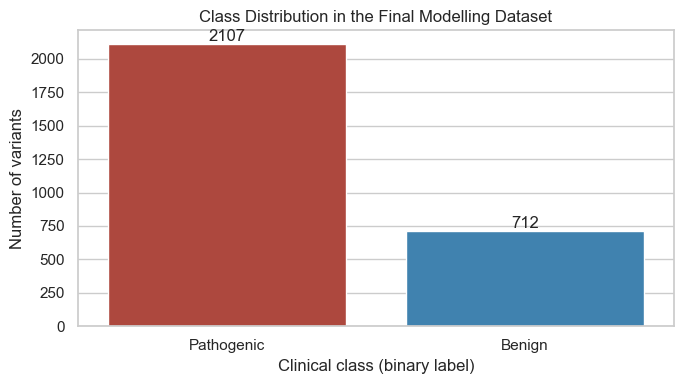

In [10]:
plot_df = model_df.assign(Class=model_df["Label"].map({1: "Pathogenic", 0: "Benign"}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=plot_df, x="Class", hue="Class", palette=["#c0392b", "#2e86c1"], legend=False, ax=ax)
ax.set_title("Class Distribution in the Final Modelling Dataset")
ax.set_xlabel("Clinical class (binary label)")
ax.set_ylabel("Number of variants")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

,Records,Pathogenic,Benign,Pathogenic %
Gene,,,,
CFTR,292,275,17,94.2
BRCA1,701,234,467,33.4
TP53,421,256,165,60.8
HBB,112,92,20,82.1
LDLR,783,743,40,94.9
PAH,510,507,3,99.4


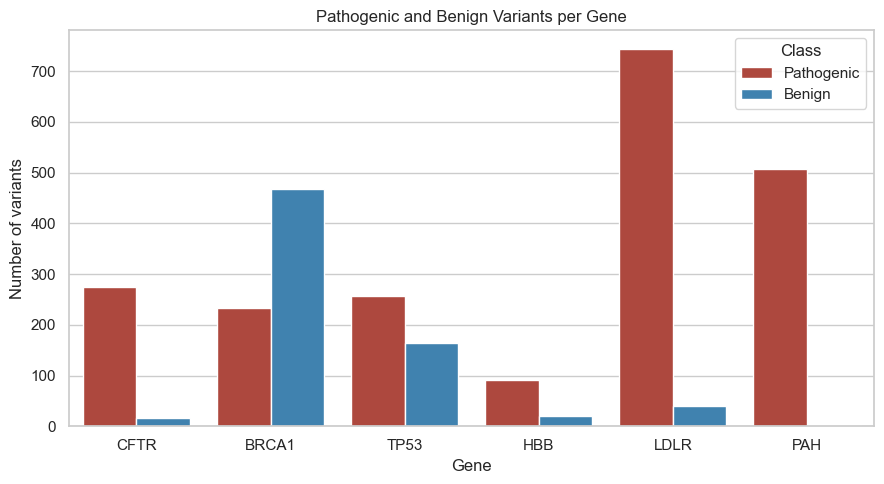

In [11]:
gene_summary = (
    model_df.assign(Pathogenic=model_df["Label"] == 1, Benign=model_df["Label"] == 0)
    .groupby("Gene")
    .agg(Records=("VariationID", "size"), Pathogenic=("Pathogenic", "sum"), Benign=("Benign", "sum"))
    .reindex(TARGET_GENES)
)
gene_summary["Pathogenic %"] = (gene_summary["Pathogenic"] / gene_summary["Records"] * 100).round(1)
display(gene_summary)

fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=plot_df, x="Gene", hue="Class", order=TARGET_GENES,
              palette=["#c0392b", "#2e86c1"], ax=ax)
ax.set_title("Pathogenic and Benign Variants per Gene")
ax.set_xlabel("Gene")
ax.set_ylabel("Number of variants")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

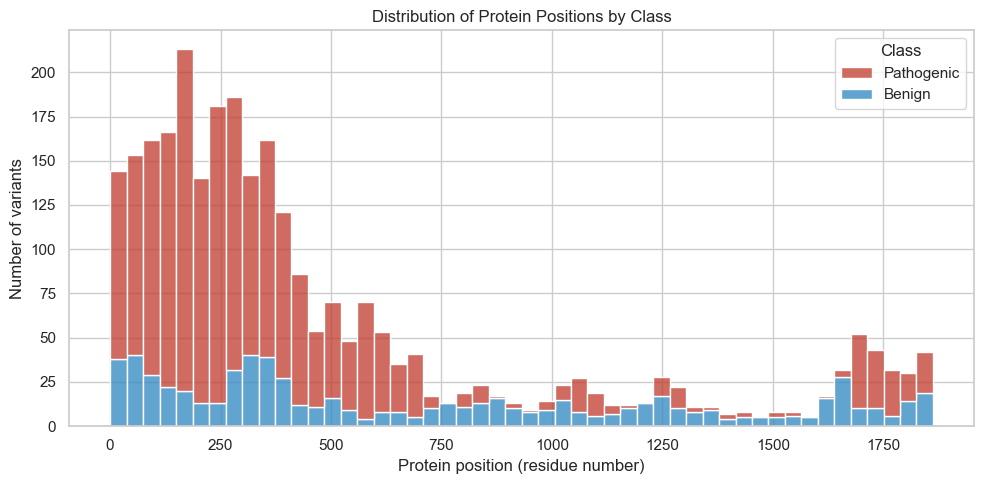

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=plot_df, x="Protein_Position", hue="Class", bins=50,
             multiple="stack", palette=["#c0392b", "#2e86c1"], ax=ax)
ax.set_title("Distribution of Protein Positions by Class")
ax.set_xlabel("Protein position (residue number)")
ax.set_ylabel("Number of variants")
plt.tight_layout()
plt.show()

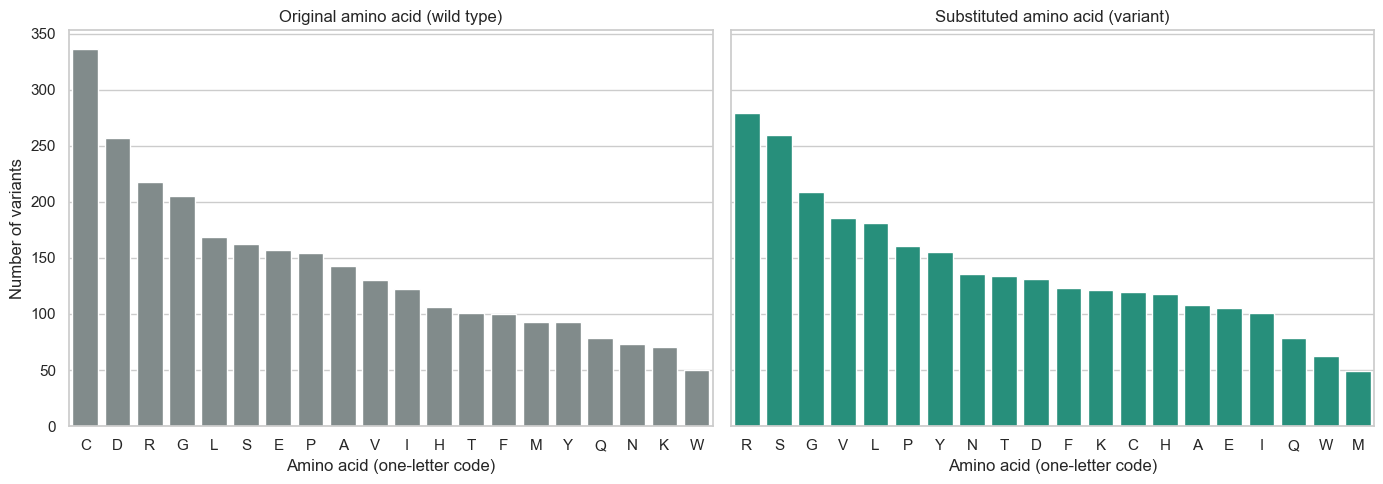

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

original_order = model_df["Original_AA"].value_counts().index
sns.countplot(data=model_df, x="Original_AA", order=original_order, color="#7f8c8d", ax=axes[0])
axes[0].set_title("Original amino acid (wild type)")
axes[0].set_xlabel("Amino acid (one-letter code)")
axes[0].set_ylabel("Number of variants")

new_order = model_df["New_AA"].value_counts().index
sns.countplot(data=model_df, x="New_AA", order=new_order, color="#16a085", ax=axes[1])
axes[1].set_title("Substituted amino acid (variant)")
axes[1].set_xlabel("Amino acid (one-letter code)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

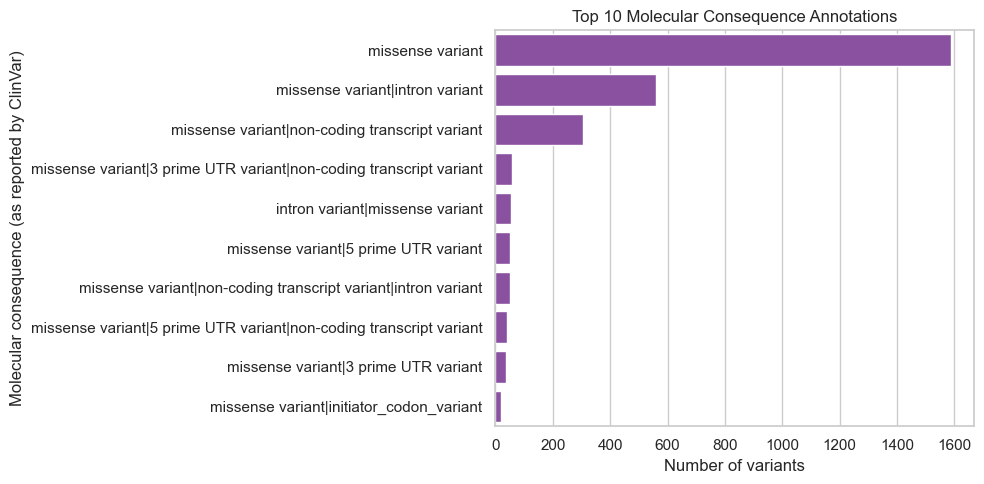

In [14]:
consequence_counts = model_df["Molecular consequence"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=consequence_counts.values, y=consequence_counts.index, color="#8e44ad", ax=ax)
ax.set_title("Top 10 Molecular Consequence Annotations")
ax.set_xlabel("Number of variants")
ax.set_ylabel("Molecular consequence (as reported by ClinVar)")
plt.tight_layout()
plt.show()

## 9. Feature Selection

Six features are used. The target is `Label`. Identifiers (`VariationID`, `Accession`, `AlleleID(s)`), the disease name (`Condition(s)`), and the original classification text are never used as inputs, because each one either identifies a record or reveals the answer.

In [15]:
FEATURES = [
    "Gene",
    "Variant type",
    "Molecular consequence",
    "Protein_Position",
    "Original_AA",
    "New_AA",
]
CATEGORICAL_FEATURES = ["Gene", "Variant type", "Molecular consequence", "Original_AA", "New_AA"]
NUMERIC_FEATURES = ["Protein_Position"]
TARGET = "Label"

FORBIDDEN_INPUTS = ["Germline classification", "Condition(s)", "VariationID", "Accession", "AlleleID(s)"]
assert not set(FEATURES) & set(FORBIDDEN_INPUTS), "A forbidden column is being used as a feature"
assert set(CATEGORICAL_FEATURES) | set(NUMERIC_FEATURES) == set(FEATURES)

X = model_df[FEATURES]
y = model_df[TARGET]
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

Feature matrix: (2819, 6)
Target vector: (2819,)


## 10. Train–Test Split

An 80/20 split, stratified on the label so both sets keep the same class balance. Fixed `random_state` makes the split reproducible.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_summary = pd.DataFrame(
    {
        "Records": [len(X_train), len(X_test)],
        "Benign (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
        "Pathogenic (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
    },
    index=["Train", "Test"],
)
display(split_summary)

,Records,Benign (0),Pathogenic (1)
Train,2255,570,1685
Test,564,142,422


## 11. Preprocessing Pipeline

Categorical features are one-hot encoded (unseen categories are ignored rather than crashing). The numerical position is standardised. Both steps live inside a scikit-learn `Pipeline`, so they are fitted only on training data whenever the model is fitted, which prevents information from the test set entering the preprocessing.

In [17]:
def build_preprocessor(categorical, numeric):
    """One-hot encode categorical features and standardise numeric features."""
    transformers = [("categorical", OneHotEncoder(handle_unknown="ignore"), categorical)]
    if numeric:
        transformers.append(("numerical", StandardScaler(), numeric))
    return ColumnTransformer(transformers=transformers)


def build_model(categorical, numeric):
    """Preprocessing and the baseline Random Forest, bundled as one pipeline."""
    return Pipeline(
        steps=[
            ("preprocessor", build_preprocessor(categorical, numeric)),
            ("classifier", RandomForestClassifier(**RF_PARAMS)),
        ]
    )

## 12. Random Forest Training

The baseline configuration is fixed in `RF_PARAMS` (300 trees, balanced class weights, seed 42). It is not tuned, because the project goal is an interpretable baseline rather than the highest score.

In [18]:
rf_model = build_model(CATEGORICAL_FEATURES, NUMERIC_FEATURES)
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")
print("Trees:", rf_model.named_steps["classifier"].n_estimators)

Random Forest training completed.
Trees: 300


## 13. Model Evaluation

Metrics are computed on the held-out 20% test set. Pathogenic is the positive class. A majority-class baseline is included so the scores can be read against a trivial predictor.

In [19]:
def evaluate(y_true, y_pred):
    """Return the headline metrics, with Pathogenic (1) as the positive class."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
    }


majority_baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
test_predictions = rf_model.predict(X_test)

metrics_table = pd.DataFrame(
    {
        "Random Forest": evaluate(y_test, test_predictions),
        "Majority-class baseline": evaluate(y_test, majority_baseline.predict(X_test)),
    }
).T.round(4)
display(metrics_table)

,Accuracy,Precision,Recall,F1,Balanced accuracy
Random Forest,0.9202,0.9274,0.9692,0.9479,0.8719
Majority-class baseline,0.7482,0.7482,1.0000,0.8560,0.5000


              precision    recall  f1-score   support

      Benign       0.89      0.77      0.83       142
  Pathogenic       0.93      0.97      0.95       422

    accuracy                           0.92       564
   macro avg       0.91      0.87      0.89       564
weighted avg       0.92      0.92      0.92       564



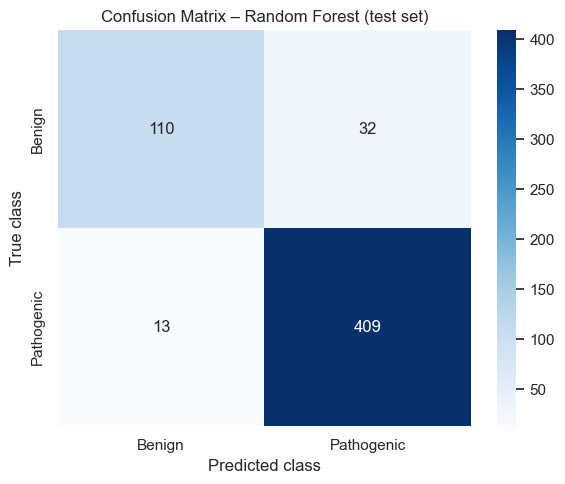

In [20]:
CLASS_NAMES = ["Benign", "Pathogenic"]

print(classification_report(y_test, test_predictions, target_names=CLASS_NAMES))

cm = confusion_matrix(y_test, test_predictions)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title("Confusion Matrix – Random Forest (test set)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

### 13a. Test-set error analysis

This section reuses `y_test` and `test_predictions` created in Sections 10–13. It quantifies false positives and false negatives and lists the affected variants. The label convention is `0 = Benign` and `1 = Pathogenic`.

Run the notebook from the top before executing this cell. If you see `NameError`, restart the kernel and choose **Run All** rather than running this cell alone.


In [21]:
# Reuse the prediction variable already created in Section 13.
assert "y_test" in globals(), "Run the train-test split and model evaluation cells first."
assert "test_predictions" in globals(), "Run the Random Forest evaluation cell first."

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows = true class; columns = predicted class)")
print(cm)
print(f"True benign: {tn}")
print(f"Benign incorrectly predicted pathogenic (false positives): {fp}")
print(f"Pathogenic incorrectly predicted benign (false negatives): {fn}")
print(f"True pathogenic: {tp}")

# Attach test-set outcomes to the corresponding source records.
error_analysis = model_df.loc[X_test.index, [
    "VariationID", "Gene", "Name", "Germline classification",
    "Protein_Position", "Original_AA", "New_AA", "Label"
]].copy()
error_analysis["Predicted_Label"] = np.asarray(test_predictions)
error_analysis["Predicted_Class"] = error_analysis["Predicted_Label"].map(
    {0: "Benign", 1: "Pathogenic"}
)
error_analysis["Actual_Class"] = error_analysis["Label"].map(
    {0: "Benign", 1: "Pathogenic"}
)
error_analysis["Prediction_Result"] = np.where(
    error_analysis["Label"] == error_analysis["Predicted_Label"],
    "Correct", "Incorrect"
)

false_positives = error_analysis[
    (error_analysis["Label"] == 0) & (error_analysis["Predicted_Label"] == 1)
].sort_values(["Gene", "VariationID"])
false_negatives = error_analysis[
    (error_analysis["Label"] == 1) & (error_analysis["Predicted_Label"] == 0)
].sort_values(["Gene", "VariationID"])

print("\\nFalse-positive records:", len(false_positives))
display(false_positives.head(30))
print("\\nFalse-negative records:", len(false_negatives))
display(false_negatives.head(30))

# Per-gene error counts; these are descriptive because each gene has a different sample size.
gene_error_summary = (
    error_analysis.assign(
        False_Positive=lambda d: (d["Label"].eq(0) & d["Predicted_Label"].eq(1)),
        False_Negative=lambda d: (d["Label"].eq(1) & d["Predicted_Label"].eq(0)),
        Correct=lambda d: d["Label"].eq(d["Predicted_Label"]),
    )
    .groupby("Gene")
    .agg(
        Test_Records=("VariationID", "size"),
        Correct=("Correct", "sum"),
        False_Positives=("False_Positive", "sum"),
        False_Negatives=("False_Negative", "sum"),
    )
)
gene_error_summary["Accuracy"] = (
    gene_error_summary["Correct"] / gene_error_summary["Test_Records"]
).round(3)
display(gene_error_summary.sort_values("Test_Records", ascending=False))


Confusion matrix (rows = true class; columns = predicted class)
[[110  32]
 [ 13 409]]
True benign: 110
Benign incorrectly predicted pathogenic (false positives): 32
Pathogenic incorrectly predicted benign (false negatives): 13
True pathogenic: 409
\nFalse-positive records: 32


,VariationID,Gene,Name,Germline classification,Protein_Position,Original_AA,New_AA,Label,Predicted_Label,Predicted_Class,Actual_Class,Prediction_Result
11073,37689,BRCA1,NM_007294.4(BRCA1):c.641A>G (p.Asp214Gly),Benign,214,D,G,0,1,Pathogenic,Benign,Incorrect
5573,41833,BRCA1,NM_007294.4(BRCA1):c.5579A>C (p.His1860Pro),Benign,1860,H,P,0,1,Pathogenic,Benign,Incorrect
7709,55154,BRCA1,NM_007294.4(BRCA1):c.4255G>C (p.Glu1419Gln),Benign,1419,E,Q,0,1,Pathogenic,Benign,Incorrect
6318,55481,BRCA1,NM_007294.4(BRCA1):c.5252G>A (p.Arg1751Gln),Benign,1751,R,Q,0,1,Pathogenic,Benign,Incorrect
6282,441431,BRCA1,NM_007294.4(BRCA1):c.5269G>T (p.Asp1757Tyr),Likely benign,1757,D,Y,0,1,Pathogenic,Benign,Incorrect
6504,531248,BRCA1,NM_007294.4(BRCA1):c.5168T>C (p.Ile1723Thr),Likely benign,1723,I,T,0,1,Pathogenic,Benign,Incorrect
11950,865041,BRCA1,NM_007294.4(BRCA1):c.52A>C (p.Met18Leu),Likely benign,18,M,L,0,1,Pathogenic,Benign,Incorrect
6276,867299,BRCA1,NM_007294.4(BRCA1):c.5271C>G (p.Asp1757Glu),Likely benign,1757,D,E,0,1,Pathogenic,Benign,Incorrect
5893,867392,BRCA1,NM_007294.4(BRCA1):c.5439T>A (p.Asp1813Glu),Likely benign,1813,D,E,0,1,Pathogenic,Benign,Incorrect
6270,867917,BRCA1,NM_007294.4(BRCA1):c.5274A>T (p.Arg1758Ser),Likely benign,1758,R,S,0,1,Pathogenic,Benign,Incorrect


\nFalse-negative records: 13


,VariationID,Gene,Name,Germline classification,Protein_Position,Original_AA,New_AA,Label,Predicted_Label,Predicted_Class,Actual_Class,Prediction_Result
7312,37604,BRCA1,NM_007294.4(BRCA1):c.4675G>A (p.Glu1559Lys),Pathogenic,1559,E,K,1,0,Benign,Pathogenic,Incorrect
7480,245697,BRCA1,NM_007294.4(BRCA1):c.4484G>C (p.Arg1495Thr),Pathogenic,1495,R,T,1,0,Benign,Pathogenic,Incorrect
11893,252890,BRCA1,NM_007294.4(BRCA1):c.77T>A (p.Ile26Asn),Pathogenic,26,I,N,1,0,Benign,Pathogenic,Incorrect
6220,267594,BRCA1,NM_007294.4(BRCA1):c.5297T>A (p.Ile1766Asn),Pathogenic/Likely pathogenic,1766,I,N,1,0,Benign,Pathogenic,Incorrect
10779,2445397,BRCA1,NM_007294.4(BRCA1):c.953A>T (p.His318Leu),Likely pathogenic,318,H,L,1,0,Benign,Pathogenic,Incorrect
7656,2687847,BRCA1,NM_007294.4(BRCA1):c.4321G>A (p.Asp1441Asn),Likely pathogenic,1441,D,N,1,0,Benign,Pathogenic,Incorrect
12088,250981,LDLR,NM_000527.5(LDLR):c.44T>C (p.Leu15Pro),Likely pathogenic,15,L,P,1,0,Benign,Pathogenic,Incorrect
12386,251223,LDLR,NM_000527.5(LDLR):c.440C>T (p.Thr147Ile),Likely pathogenic,147,T,I,1,0,Benign,Pathogenic,Incorrect
13336,251897,LDLR,NM_000527.5(LDLR):c.1558A>G (p.Arg520Gly),Pathogenic/Likely pathogenic,520,R,G,1,0,Benign,Pathogenic,Incorrect
12087,1436912,LDLR,NM_000527.5(LDLR):c.44T>G (p.Leu15Arg),Likely pathogenic,15,L,R,1,0,Benign,Pathogenic,Incorrect


,Test_Records,Correct,False_Positives,False_Negatives,Accuracy
Gene,,,,,
LDLR,156,146,6,4,0.936
BRCA1,134,117,11,6,0.873
PAH,109,109,0,0,1.000
CFTR,70,68,2,0,0.971
TP53,70,58,9,3,0.829
HBB,25,21,4,0,0.840


Read the two class rows separately. Benign is the minority class, so its precision and recall are the numbers most sensitive to the class imbalance. Pathogenic precision and recall describe the majority class and tend to look high even when benign performance is weak.

## 14. Additional Validation

### 14a. Gene-held-out evaluation (leave-one-gene-out)

A random split lets every gene appear in both training and test data, so the model can use gene-level patterns it has already seen. To test generalisation to **unseen genes**, each gene is held out in turn: the model trains on the other five and is scored on the held-out gene.

Two notes for reading the table:
- Each held-out gene has a different class balance, so compare each model's accuracy with the majority-class accuracy for that gene.
- If a held-out gene contains only one class, balanced accuracy equals the recall for that class.

In [22]:
groups = model_df["Gene"]
gene_holdout_rows = []

for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups=groups):
    held_out_gene = groups.iloc[test_idx].iloc[0]
    y_fold_train = y.iloc[train_idx]
    y_fold_test = y.iloc[test_idx]

    fold_model = build_model(CATEGORICAL_FEATURES, NUMERIC_FEATURES)
    fold_model.fit(X.iloc[train_idx], y_fold_train)
    fold_predictions = fold_model.predict(X.iloc[test_idx])

    fold_majority = int(y_fold_train.mode().iloc[0])
    gene_holdout_rows.append({
        "Held-out gene": held_out_gene,
        "Test records": len(test_idx),
        "Benign": int((y_fold_test == 0).sum()),
        "Pathogenic": int((y_fold_test == 1).sum()),
        "RF accuracy": accuracy_score(y_fold_test, fold_predictions),
        "Majority accuracy": accuracy_score(y_fold_test, np.full(len(y_fold_test), fold_majority)),
        "RF balanced accuracy": balanced_accuracy_score(y_fold_test, fold_predictions),
    })

gene_holdout = pd.DataFrame(gene_holdout_rows).set_index("Held-out gene").round(3)
display(gene_holdout)

print("Mean RF accuracy across held-out genes:", round(gene_holdout["RF accuracy"].mean(), 3))
print("Mean majority accuracy across held-out genes:", round(gene_holdout["Majority accuracy"].mean(), 3))

,Test records,Benign,Pathogenic,RF accuracy,Majority accuracy,RF balanced accuracy
Held-out gene,,,,,,
BRCA1,701,467,234,0.340,0.334,0.458
CFTR,292,17,275,0.904,0.942,0.563
HBB,112,20,92,0.812,0.821,0.495
LDLR,783,40,743,0.576,0.949,0.434
PAH,510,3,507,0.982,0.994,0.660
TP53,421,165,256,0.599,0.608,0.502


Mean RF accuracy across held-out genes: 0.702
Mean majority accuracy across held-out genes: 0.775


### 14b. Protein-change-grouped validation

The random split can place records with the same amino-acid substitution in both training and test sets. This additional five-fold validation keeps identical protein changes together in one fold.

The group key is `Gene + Protein_Position + Original_AA + New_AA`. This is a stricter test against overlap of the same protein substitution, but it is not a test of unseen genes. The six-gene leave-one-gene-out evaluation above addresses that separate question.

This cell may take several minutes because it fits five additional Random Forest models.


In [23]:
PROTEIN_GROUP_COLUMNS = ["Gene", "Protein_Position", "Original_AA", "New_AA"]
protein_groups = (
    model_df[PROTEIN_GROUP_COLUMNS].astype(str).agg("|".join, axis=1)
)

group_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

group_cv_rows = []
for fold_number, (train_idx, test_idx) in enumerate(
    group_cv.split(X, y, groups=protein_groups), start=1
):
    train_groups = set(protein_groups.iloc[train_idx])
    test_groups = set(protein_groups.iloc[test_idx])
    assert train_groups.isdisjoint(test_groups), (
        f"Protein groups overlap in fold {fold_number}"
    )

    fold_model = build_model(CATEGORICAL_FEATURES, NUMERIC_FEATURES)
    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])
    fold_pred = fold_model.predict(X.iloc[test_idx])

    fold_metrics = evaluate(y.iloc[test_idx], fold_pred)
    group_cv_rows.append({
        "Fold": fold_number,
        "Test records": len(test_idx),
        **fold_metrics,
    })

protein_group_cv_results = pd.DataFrame(group_cv_rows).set_index("Fold")
display(protein_group_cv_results.round(4))

print("\\nMean ± standard deviation across protein-grouped folds:")
for metric in ["Accuracy", "Precision", "Recall", "F1", "Balanced accuracy"]:
    mean_value = protein_group_cv_results[metric].mean()
    std_value = protein_group_cv_results[metric].std(ddof=1)
    print(f"{metric}: {mean_value:.4f} ± {std_value:.4f}")


,Test records,Accuracy,Precision,Recall,F1,Balanced accuracy
Fold,,,,,,
1,564,0.8954,0.9153,0.9479,0.9313,0.8437
2,564,0.9184,0.9273,0.9668,0.9466,0.8707
3,564,0.9060,0.9163,0.9620,0.9386,0.8516
4,564,0.9149,0.9210,0.9691,0.9444,0.8622
5,563,0.9325,0.9402,0.9715,0.9556,0.8942


\nMean ± standard deviation across protein-grouped folds:
Accuracy: 0.9135 ± 0.0139
Precision: 0.9240 ± 0.0102
Recall: 0.9635 ± 0.0094
F1: 0.9433 ± 0.0091
Balanced accuracy: 0.8645 ± 0.0195


### 14c. Baselines on the random split

These comparisons show how much of the performance comes from the gene alone, and how much the substitution features add. They use the same split and the same pipeline as the main model.

In [24]:
def random_split_scores(feature_list):
    """Fit the baseline pipeline on a feature subset and score it on the shared test split."""
    categorical = [f for f in feature_list if f in CATEGORICAL_FEATURES]
    numeric = [f for f in feature_list if f in NUMERIC_FEATURES]
    model = build_model(categorical, numeric)
    model.fit(X_train[feature_list], y_train)
    return evaluate(y_test, model.predict(X_test[feature_list]))


feature_sets = {
    "Gene only": ["Gene"],
    "Without Gene": [f for f in FEATURES if f != "Gene"],
    "All six features": FEATURES,
}
baseline_comparison = pd.DataFrame(
    {name: random_split_scores(cols) for name, cols in feature_sets.items()}
).T.round(4)
display(baseline_comparison)

,Accuracy,Precision,Recall,F1,Balanced accuracy
Gene only,0.8333,0.9556,0.8152,0.8798,0.8512
Without Gene,0.8848,0.9085,0.9408,0.9243,0.8295
All six features,0.9202,0.9274,0.9692,0.9479,0.8719


## 15. SHAP Explainability

SHAP splits each prediction into contributions from individual features. Positive values push the output toward **Pathogenic**, negative values push it toward **Benign**.

Two cautions apply throughout:
- SHAP describes what the model relies on. It does not show that a feature is biologically causal.
- One-hot columns are yes/no indicators. Standardised `Protein_Position` values are z-scores, not residue numbers.

The explanation uses a fixed random sample of 100 test records, for speed and reproducibility.

In [25]:
preprocessor = rf_model.named_steps["preprocessor"]
classifier = rf_model.named_steps["classifier"]
assert list(classifier.classes_) == [0, 1], "Class order must be [0, 1] so index 1 is Pathogenic"

encoded_test = preprocessor.transform(X_test)
if hasattr(encoded_test, "toarray"):
    encoded_test = encoded_test.toarray()

feature_names = [
    name.replace("categorical__", "").replace("numerical__", "")
    for name in preprocessor.get_feature_names_out()
]
encoded_test_df = pd.DataFrame(encoded_test, columns=feature_names, index=X_test.index)
shap_sample = encoded_test_df.sample(n=100, random_state=RANDOM_STATE)
n_samples, n_features = shap_sample.shape

explainer = shap.TreeExplainer(classifier)
raw_shap_values = explainer.shap_values(shap_sample)


def select_pathogenic_shap(raw, n_samples, n_features):
    """
    Return (values, format_name) where values has shape (samples, features)
    and holds the SHAP values for the Pathogenic class (class index 1).

    Supported outputs:
      - list of per-class arrays, each (samples, features)
      - 3D array (samples, features, classes)
      - 3D array (classes, samples, features)
      - 2D array (samples, features), treated as single-output values
    Any other shape raises ValueError.
    """
    if isinstance(raw, list):
        if len(raw) != 2:
            raise ValueError(f"Expected 2 per-class SHAP arrays for binary classification, got {len(raw)}.")
        values = np.asarray(raw[1])
        fmt = "list of per-class arrays (class 1 selected)"
    else:
        values = np.asarray(raw)
        if values.ndim == 3 and values.shape == (n_samples, n_features, 2):
            values = values[:, :, 1]
            fmt = "3D (samples, features, classes); class 1 selected"
        elif values.ndim == 3 and values.shape == (2, n_samples, n_features):
            values = values[1]
            fmt = "3D (classes, samples, features); class 1 selected"
        elif values.ndim == 2 and values.shape == (n_samples, n_features):
            fmt = "2D (samples, features); single-output values"
        else:
            raise ValueError(
                f"Unsupported SHAP output shape {values.shape}. Expected (samples, features, classes), "
                f"(classes, samples, features), (samples, features), or a list of two arrays."
            )
    if values.shape != (n_samples, n_features):
        raise ValueError(
            f"Selected Pathogenic SHAP values have shape {values.shape}, "
            f"expected {(n_samples, n_features)}."
        )
    return values, fmt


shap_pathogenic, shap_format = select_pathogenic_shap(raw_shap_values, n_samples, n_features)
print("SHAP output format detected:", shap_format)

expected = np.atleast_1d(explainer.expected_value)
if expected.size == 2:
    base_value_pathogenic = float(expected[1])
elif expected.size == 1:
    base_value_pathogenic = float(expected[0])
else:
    raise ValueError(f"Unexpected expected_value size: {expected.size}")

# Class-selection check: base value plus SHAP contributions should reproduce
# the Pathogenic probability. A mismatch means the wrong class or scale was used.
pathogenic_proba = classifier.predict_proba(shap_sample.values)[:, 1]
reconstructed = base_value_pathogenic + shap_pathogenic.sum(axis=1)
max_gap = float(np.max(np.abs(reconstructed - pathogenic_proba)))
if max_gap > 1e-3:
    raise ValueError(
        f"SHAP additivity check failed (max gap {max_gap:.4g}). "
        "The selected values do not reproduce the Pathogenic probability."
    )

print("SHAP values computed for", n_samples, "records and", n_features, "features.")
print("Base value (pathogenic):", round(base_value_pathogenic, 4))
print("Additivity check passed (max gap {:.2e}).".format(max_gap))

SHAP output format detected: 3D (samples, features, classes); class 1 selected
SHAP values computed for 100 records and 79 features.
Base value (pathogenic): 0.4996
Additivity check passed (max gap 5.95e-09).


### Global explainability

Mean absolute SHAP value shows how strongly each feature moves predictions on average. The beeswarm plot shows the direction of each effect: each dot is one variant, and colour shows the feature's value.

In [26]:
importance_df = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mean |SHAP| (pathogenic)": np.abs(shap_pathogenic).mean(axis=0),
    })
    .sort_values("Mean |SHAP| (pathogenic)", ascending=False)
    .reset_index(drop=True)
)
display(importance_df.head(15))

,Feature,Mean |SHAP| (pathogenic)
0,Gene_BRCA1,0.103074
1,Molecular consequence_missense variant,0.089113
2,Protein_Position,0.073520
3,Gene_LDLR,0.054421
4,Gene_PAH,0.041284
5,Gene_TP53,0.036411
6,Molecular consequence_missense variant|intron ...,0.031948
7,Original_AA_C,0.023960
8,Gene_CFTR,0.023391
9,Molecular consequence_missense variant|non-cod...,0.016845


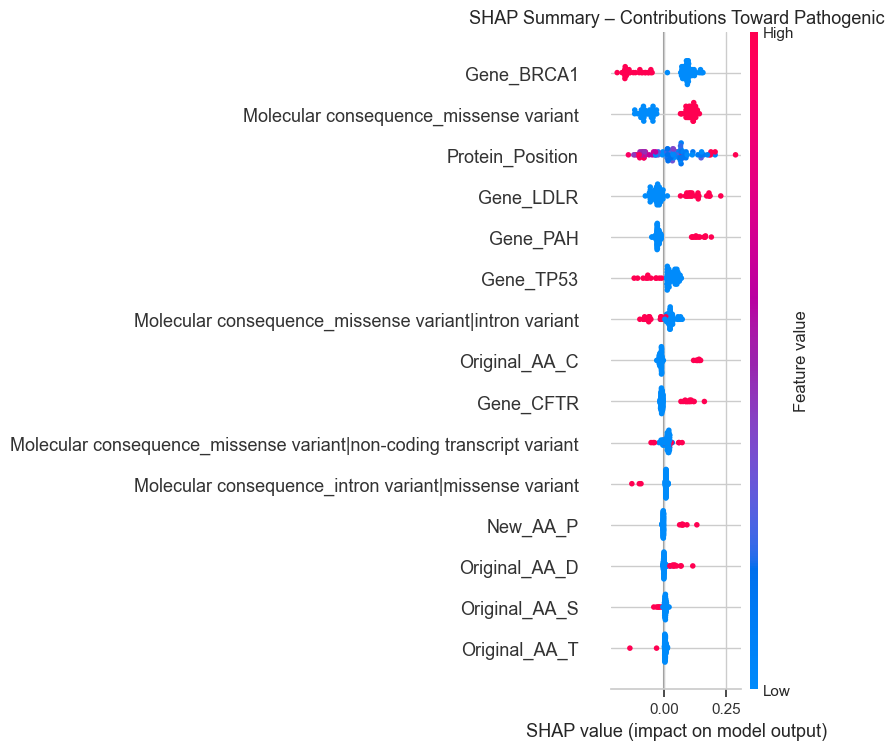

In [27]:
shap.summary_plot(shap_pathogenic, shap_sample, max_display=15, show=False)
plt.title("SHAP Summary – Contributions Toward Pathogenic", fontsize=13)
plt.show()

### Local explainability

One example variant is explained in detail. The preferred example is VariationID 811500 (HBB, p.His93Gln) if it is in the sample. Otherwise the first sampled record is used. The waterfall plot starts at the base value and adds each feature's contribution to reach the model's output for this record.

In [28]:
PREFERRED_VARIATION_ID = 811500
sampled_ids = model_df.loc[shap_sample.index, "VariationID"]

if (sampled_ids == PREFERRED_VARIATION_ID).any():
    example_index = sampled_ids.index[sampled_ids == PREFERRED_VARIATION_ID][0]
else:
    example_index = shap_sample.index[0]

example_position = shap_sample.index.get_loc(example_index)
example_record = model_df.loc[example_index]

example_proba = rf_model.predict_proba(X_test.loc[[example_index]])[0] if example_index in X_test.index else None
print("VariationID:", example_record["VariationID"])
print("Gene:", example_record["Gene"], "| Name:", example_record["Name"])
print("Recorded ClinVar class:", example_record["Germline classification"])
if example_proba is not None:
    print("Predicted pathogenic probability: {:.2%}".format(example_proba[1]))

VariationID: 54604
Gene: BRCA1 | Name: NM_007294.4(BRCA1):c.2566T>C (p.Tyr856His)
Recorded ClinVar class: Benign
Predicted pathogenic probability: 1.00%


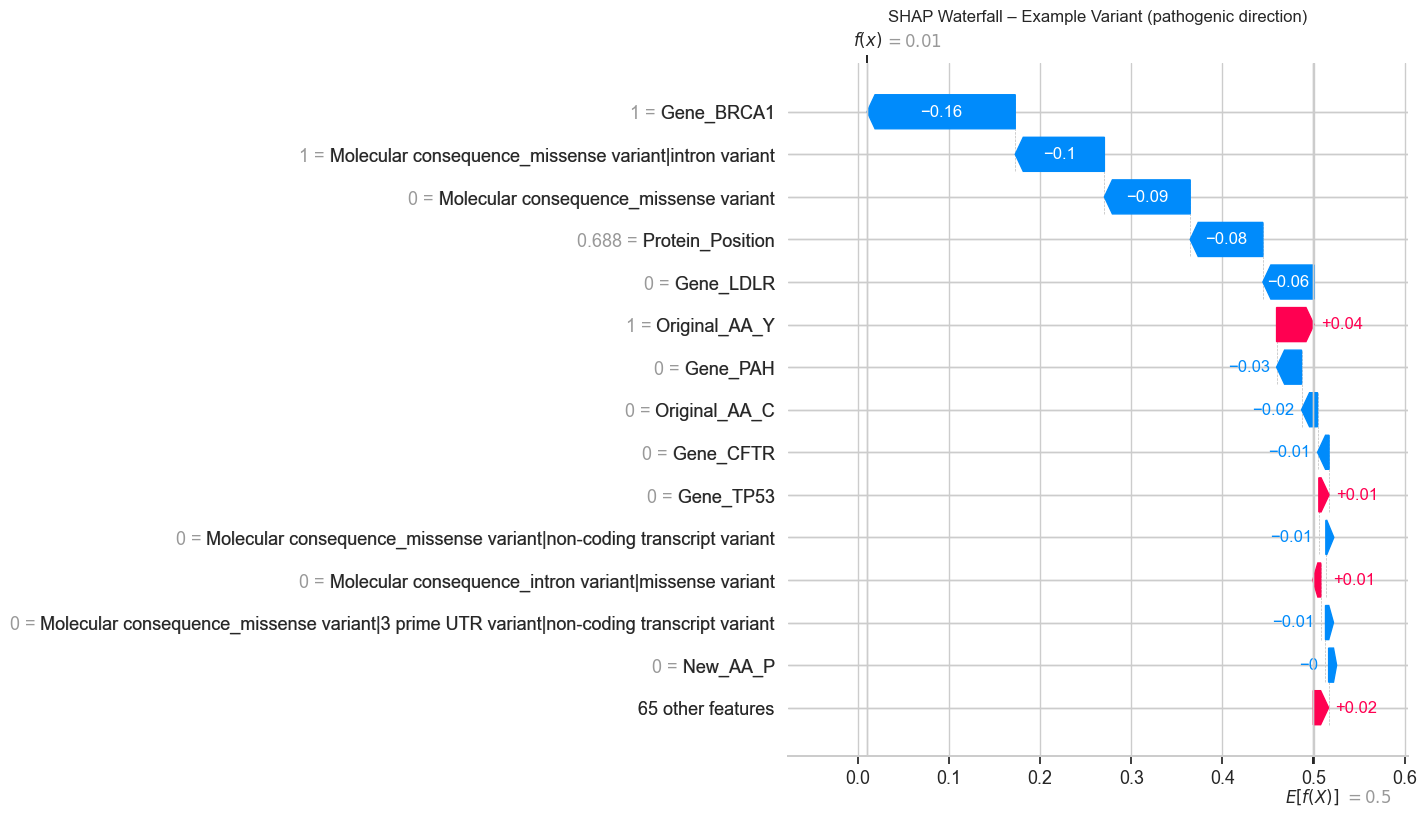

Strongest pushes toward Benign:


,SHAP value
Gene_BRCA1,-0.162601
Molecular consequence_missense variant|intron variant,-0.097827
Molecular consequence_missense variant,-0.094180
Protein_Position,-0.079742
Gene_LDLR,-0.056098


Strongest pushes toward Pathogenic:


,SHAP value
Original_AA_Y,0.041069
Gene_TP53,0.011244
Molecular consequence_intron variant|missense variant,0.005561
Original_AA_S,0.002868
Original_AA_N,0.002811


In [29]:
example_explanation = shap.Explanation(
    values=shap_pathogenic[example_position],
    base_values=base_value_pathogenic,
    data=shap_sample.iloc[example_position].values,
    feature_names=feature_names,
)
shap.plots.waterfall(example_explanation, max_display=15, show=False)
plt.title("SHAP Waterfall – Example Variant (pathogenic direction)", fontsize=12)
plt.show()

contributions = pd.Series(shap_pathogenic[example_position], index=feature_names).sort_values()
print("Strongest pushes toward Benign:")
display(contributions.head(5).rename("SHAP value").to_frame())
print("Strongest pushes toward Pathogenic:")
display(contributions.tail(5).iloc[::-1].rename("SHAP value").to_frame())

## 16. Save Processed Data, Model, and Lookup Table

Three outputs are written:

1. `data/processed/clinvar_labeled.csv` – final labelled modelling table (all raw columns plus the engineered features).
2. `data/processed/variant_lookup.csv` – the columns the Streamlit app uses to look up a variant.
3. `models/random_forest_clinvar.pkl` – the complete pipeline (preprocessing plus Random Forest), fitted on the training split.

The saved files are then reloaded and checked against the in-memory model.

In [30]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

LABELED_CSV = PROCESSED_DIR / "clinvar_labeled.csv"
LOOKUP_CSV = PROCESSED_DIR / "variant_lookup.csv"
MODEL_PATH = MODELS_DIR / "random_forest_clinvar.pkl"

LOOKUP_COLUMNS = [
    "VariationID", "Accession", "Gene", "Name", "Protein change",
    "Germline classification", "Label", "Variant type", "Molecular consequence",
    "Protein_Position", "Original_AA", "New_AA",
]

model_df.to_csv(LABELED_CSV, index=False)

variant_lookup = model_df[LOOKUP_COLUMNS].drop_duplicates(subset=["VariationID"])
variant_lookup.to_csv(LOOKUP_CSV, index=False)

joblib.dump(rf_model, MODEL_PATH)

print("Saved:", LABELED_CSV.relative_to(PROJECT_ROOT), "-", len(model_df), "rows")
print("Saved:", LOOKUP_CSV.relative_to(PROJECT_ROOT), "-", len(variant_lookup), "rows")
print("Saved:", MODEL_PATH.relative_to(PROJECT_ROOT))

Saved: data\processed\clinvar_labeled.csv - 2819 rows
Saved: data\processed\variant_lookup.csv - 2819 rows
Saved: models\random_forest_clinvar.pkl


In [31]:
# Reload the saved files and confirm they reproduce the in-memory results.
loaded_model = joblib.load(MODEL_PATH)
check_X = X_test.head(5)

assert np.array_equal(loaded_model.predict(check_X), rf_model.predict(check_X)), "Reloaded predictions differ"
assert np.allclose(loaded_model.predict_proba(check_X), rf_model.predict_proba(check_X)), "Reloaded probabilities differ"

lookup_check = pd.read_csv(LOOKUP_CSV)
assert list(lookup_check.columns) == LOOKUP_COLUMNS, "Lookup columns do not match the expected schema"
assert len(lookup_check) == len(variant_lookup), "Lookup row count changed on reload"
assert lookup_check["VariationID"].is_unique, "Duplicate VariationID in lookup"

print("Reloaded model reproduces predictions and probabilities.")
print("Lookup file has the expected", len(LOOKUP_COLUMNS), "columns and", len(lookup_check), "unique variants.")

Reloaded model reproduces predictions and probabilities.
Lookup file has the expected 12 columns and 2819 unique variants.


## 17. Limitations and Conclusion

**What the model learns.** The labels come entirely from ClinVar classifications. The model reproduces patterns in this one snapshot, not the underlying biology.

**Gene imbalance.** The classes are very unevenly spread across genes. In the earlier exploratory run, several genes were dominated by one class (PAH and LDLR were overwhelmingly pathogenic, and CFTR was mostly pathogenic), while BRCA1 was mostly benign. A model can score well by recognising the gene, so the gene-only baseline in Section 14b is essential context for the full model's score.

**Random versus unseen-gene performance.** A random split allows every gene in training and testing, so it overstates how well the model would handle a gene it has never seen. The leave-one-gene-out results in Section 14a are the more demanding test. Where they are weak, the model should not be expected to generalise to new genes.

**Feature scope.** Only six features are used: the gene, variant type, molecular consequence, residue position, and the two amino acids. These capture little of protein structure, conservation, or functional context. Single-residue substitutions are modelled, and complex in-frame changes are excluded (see Section 6).

**Excluded records.** Uncertain, conflicting, and other unsupported classifications are excluded, records that name more than one selected gene (or none), and records whose `Name` does not contain exactly one amino acid substitution. Both sets are reported in Sections 5, 6, and 7. Excluding conflicting classifications also means the model never sees the hardest cases.

**Explainability.** SHAP shows which features drive the model's predictions. It does not show that those features cause disease, and it does not explain individual variants in clinical terms.

**Probabilities.** Predicted probabilities are scores from a model trained on one dataset. They are not calibrated clinical risks.

**Conclusion.** This notebook builds a reproducible, leakage-aware baseline for pathogenicity classification from six features. Its random-split performance is reported with the baselines and the leave-one-gene-out evaluation, so the strengths and weaknesses can be read together. It is an educational research prototype and is **not** suitable for clinical use.

**Additional validation to report:** Include the protein-change-grouped cross-validation mean and standard deviation from Section 14b. Compare it with the random-split result, but do not describe either as clinical performance. Report the false-positive and false-negative counts from Section 13a, and discuss which genes contribute most of those errors. The protein-grouped split prevents the same defined amino-acid substitution from crossing folds; it does not remove all biological similarity between variants.
